In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

In [19]:
df = pd.read_csv("../data/delaney-processed.csv")

In [20]:
df.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 10 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Compound ID                                      1128 non-null   object 
 1   ESOL predicted log solubility in mols per litre  1128 non-null   float64
 2   Minimum Degree                                   1128 non-null   int64  
 3   Molecular Weight                                 1128 non-null   float64
 4   Number of H-Bond Donors                          1128 non-null   int64  
 5   Number of Rings                                  1128 non-null   int64  
 6   Number of Rotatable Bonds                        1128 non-null   int64  
 7   Polar Surface Area                               1128 non-null   float64
 8   measured log solubility in mols per litre        1128 non-null   float64
 9   smiles                        

In [22]:
df.describe

<bound method NDFrame.describe of          Compound ID  ESOL predicted log solubility in mols per litre  \
0          Amigdalin                                           -0.974   
1           Fenfuram                                           -2.885   
2             citral                                           -2.579   
3             Picene                                           -6.618   
4          Thiophene                                           -2.232   
...              ...                                              ...   
1123       halothane                                           -2.608   
1124          Oxamyl                                           -0.908   
1125       Thiometon                                           -3.323   
1126  2-Methylbutane                                           -2.245   
1127        Stirofos                                           -4.320   

      Minimum Degree  Molecular Weight  Number of H-Bond Donors  \
0                  1  

In [23]:
df.describe()

,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-2.988192,1.058511,203.937074,0.701241,1.390957,2.177305,34.872881,-3.050102
std,1.683220,0.238560,102.738077,1.089727,1.318286,2.640974,35.383593,2.096441
min,-9.702000,0.000000,16.043000,0.000000,0.000000,0.000000,0.000000,-11.600000
25%,-3.948250,1.000000,121.183000,0.000000,0.000000,0.000000,0.000000,-4.317500
50%,-2.870000,1.000000,182.179000,0.000000,1.000000,1.000000,26.300000,-2.860000
75%,-1.843750,1.000000,270.372000,1.000000,2.000000,3.000000,55.440000,-1.600000
max,1.091000,2.000000,780.949000,11.000000,8.000000,23.000000,268.680000,1.580000


In [24]:
df.shape

(1128, 10)

In [25]:
df.columns.tolist()

['Compound ID',
 'ESOL predicted log solubility in mols per litre',
 'Minimum Degree',
 'Molecular Weight',
 'Number of H-Bond Donors',
 'Number of Rings',
 'Number of Rotatable Bonds',
 'Polar Surface Area',
 'measured log solubility in mols per litre',
 'smiles']

In [26]:
smiles_col = "smiles"
target_col = "measured log solubility in mols per litre"

In [27]:
df[[smiles_col, target_col]].head()

,smiles,measured log solubility in mols per litre
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,CC(C)=CCCC(C)=CC(=O),-2.06
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,c1ccsc1,-1.33


In [28]:
smiles = df.loc[0, "smiles"]

mol = Chem.MolFromSmiles(smiles)

mol

In [29]:
print(Chem.MolToSmiles(mol))

N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1


In [30]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [31]:
calculate_descriptors("CCO")

{'MolWt': 46.069,
 'LogP': -0.0014000000000000123,
 'HBD': 1,
 'HBA': 1,
 'TPSA': 20.23,
 'RotatableBonds': 0,
 'Rings': 0}

In [32]:
Compound_ID = df.loc[0, "Compound ID"]

print(Compound_ID)

Amigdalin


In [35]:
df[[smiles_col, target_col]].head()


,smiles,measured log solubility in mols per litre
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,CC(C)=CCCC(C)=CC(=O),-2.06
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,c1ccsc1,-1.33


In [36]:
smiles = df.loc[0, "smiles"]

mol = Chem.MolFromSmiles(smiles)

mol

In [37]:
print(Chem.MolToSmiles(mol))

N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1


In [38]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [39]:
calculate_descriptors("CCO")

{'MolWt': 46.069,
 'LogP': -0.0014000000000000123,
 'HBD': 1,
 'HBA': 1,
 'TPSA': 20.23,
 'RotatableBonds': 0,
 'Rings': 0}

In [40]:
descriptor_df = df["smiles"].apply(calculate_descriptors).apply(pd.Series)

In [41]:
descriptor_df.head()

,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [42]:
descriptor_df.shape

(1128, 7)

In [43]:
data = pd.concat(
    [
        df[[smiles_col, target_col]].reset_index(drop=True),
        descriptor_df.reset_index(drop=True)
    ],
    axis=1
)

In [44]:
data.head()

,smiles,measured log solubility in mols per litre,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,-3.30,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),-2.06,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,c1ccsc1,-1.33,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [45]:
data.isna().sum()

smiles                                       0
measured log solubility in mols per litre    0
MolWt                                        0
LogP                                         0
HBD                                          0
HBA                                          0
TPSA                                         0
RotatableBonds                               0
Rings                                        0
dtype: int64

In [46]:
data.describe()

,measured log solubility in mols per litre,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-3.050102,203.937074,2.447520,0.701241,2.111702,34.872881,2.177305,1.390957
std,2.096441,102.738077,1.852875,1.089727,2.153375,35.383593,2.640974,1.318286
min,-11.600000,16.043000,-7.571400,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-4.317500,121.183000,1.414900,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-2.860000,182.179000,2.339000,0.000000,2.000000,26.300000,1.000000,1.000000
75%,-1.600000,270.372000,3.402200,1.000000,3.000000,55.440000,3.000000,2.000000
max,1.580000,780.949000,10.388600,11.000000,16.000000,268.680000,23.000000,8.000000


In [47]:
data["MolWt"].isna().sum()

0

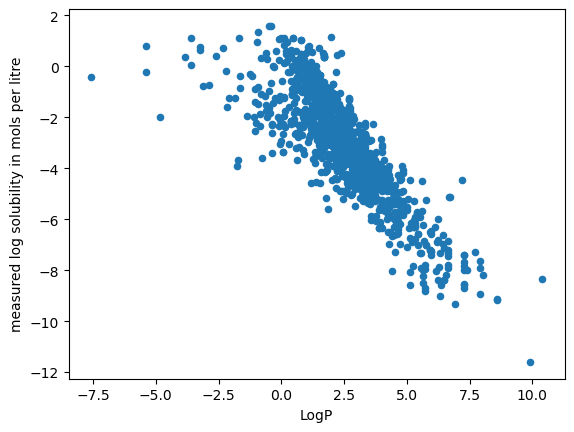

In [48]:
data.plot.scatter(
    x="LogP",
    y=target_col
)

plt.show()